# Comparative Weather and Climate Data Analysis of Astana, Milan, Paris and London Using Python

University of Milan (UNIMI) - Coding for Data Science and Data Management, academic year 2026-2027. Individual project.

**Period:** daily data, 2021-01-01 to 2025-12-31 (1826 days per city).

**Research questions**
1. Which city has the highest average annual temperature?
2. Which city experiences the greatest temperature variation?
3. Which city receives the highest amount of precipitation?
4. How do seasonal temperature patterns differ between the four cities?
5. Which city experiences the most rainy days?
6. Is there a relationship between temperature and precipitation?
7. Which city experiences the strongest winds?
8. How does Astana's climate differ from the European cities?

**Status of this notebook:** data collection, cleaning, statistics and figures are implemented in `src/`; this notebook runs them and presents the results with short observations. The final conclusions are written in Stage 9 of the project.

## 1. Data source and methodology

**Source.** Open-Meteo Historical Weather API (`archive` endpoint), free for non-commercial use. The data come from weather *reanalysis* datasets: model-based estimates that combine many types of observations. They are **not** readings from a single weather station. The default "Best Match" model selection was used (it combines ECMWF IFS, ERA5 and ERA5-Land, with grid resolution of roughly 9-25 km depending on the model); the model used for each day is not stored in the saved responses.

**Cities (coordinates used):** Astana (51.1694, 71.4491), Milan (45.4642, 9.1900), Paris (48.8566, 2.3522), London (51.5074, -0.1278).

**Variables (daily):** mean, maximum and minimum temperature at 2 m (°C); precipitation sum, including snow, and rain sum (mm); maximum 10 m wind speed (km/h); mean relative humidity at 2 m (%).

**Time handling.** Daily values are 24-hour aggregations of hourly values. Day boundaries use the UTC offset resolved when the request was made; daylight-saving changes are ignored, so in summer the European days are shifted by about one hour relative to the local clock.

**Pipeline**
1. `src/data_collection.py` downloads the data and saves one raw CSV per city in `data/raw/`.
2. `src/data_cleaning.py` converts dates, adds year/month/season, runs quality checks and saves `data/processed/weather_clean.csv`.
3. `src/analysis.py` contains the statistical functions.
4. `src/visualization.py` draws the figures (saved to `outputs/figures/` when run as a script).

**Definitions used**
- Seasons are meteorological: winter = Dec-Feb, spring = Mar-May, summer = Jun-Aug, autumn = Sep-Nov.
- Rainy day: `rain_sum` >= 1 mm (0.1 mm and 5 mm are also shown as a sensitivity check).
- Strong-wind day: daily maximum wind speed >= 40 km/h. This is the maximum of the regular 10 m wind speed, **not** wind gusts.
- Temperature variation is measured in three ways: standard deviation of daily mean temperature, range (max - min of daily mean temperature), and annual amplitude (warmest month mean - coldest month mean).
- "European mean" is the simple mean of Milan, Paris and London.

In [1]:
import sys
from pathlib import Path

# the notebook lives in notebooks/, the modules in src/
sys.path.insert(0, str(Path.cwd().parent / "src"))

import pandas as pd
from IPython.display import display

import analysis as an
import data_cleaning as dc
import visualization as viz

pd.set_option("display.width", 120)

## 2. Data exploration (raw data)

In [2]:
raw = dc.load_raw_data()
print("Shape:", raw.shape)
raw.head()

Shape: (7304, 9)


,city,time,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,wind_speed_10m_max,relative_humidity_2m_mean
0,Astana,2021-01-01,-21.7,-18.1,-30.0,0.6,0.0,10.0,82
1,Astana,2021-01-02,-29.4,-24.9,-32.0,0.0,0.0,9.8,78
2,Astana,2021-01-03,-30.0,-26.5,-33.0,0.0,0.0,13.0,71
3,Astana,2021-01-04,-23.2,-19.0,-28.3,0.0,0.0,14.8,67
4,Astana,2021-01-05,-17.8,-14.4,-22.7,0.0,0.0,19.5,65


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7304 entries, 0 to 7303
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   city                       7304 non-null   str    
 1   time                       7304 non-null   str    
 2   temperature_2m_mean        7304 non-null   float64
 3   temperature_2m_max         7304 non-null   float64
 4   temperature_2m_min         7304 non-null   float64
 5   precipitation_sum          7304 non-null   float64
 6   rain_sum                   7304 non-null   float64
 7   wind_speed_10m_max         7304 non-null   float64
 8   relative_humidity_2m_mean  7304 non-null   int64  
dtypes: float64(6), int64(1), str(2)
memory usage: 513.7 KB


In [4]:
raw.describe().round(2)

,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,wind_speed_10m_max,relative_humidity_2m_mean
count,7304.00,7304.00,7304.00,7304.00,7304.00,7304.00,7304.00
mean,10.83,15.17,6.52,2.29,2.17,17.94,74.31
std,9.68,10.31,9.30,5.39,5.34,7.63,13.77
min,-31.30,-27.80,-34.40,0.00,0.00,3.30,25.00
25%,5.70,9.40,1.80,0.00,0.00,12.10,66.00
50%,11.70,16.00,7.60,0.10,0.10,16.80,77.00
75%,17.60,22.40,13.10,2.00,1.70,22.50,85.00
max,32.00,39.10,26.40,90.30,90.30,68.00,99.00


The raw data contain 1826 rows for each of the four cities and 9 columns, with no missing values. The `time` column is stored as text and is converted to a date type during cleaning.

## 3. Data cleaning and quality checks

In [5]:
weather = dc.clean_weather(raw)
checks = dc.run_quality_checks(weather)
print(weather["time"].dtype)
checks

datetime64[us]


missing values                      0
duplicate city-date rows            0
missing days                        0
mean temp below min temp            0
mean temp above max temp            0
rain_sum above precipitation_sum    0
negative precipitation              0
humidity outside 0-100              0
dtype: int64

Cleaning converts `time` to dates and adds `year`, `month` and `season`. All quality checks above must be 0: no missing values, no duplicate city-date rows, no missing days in 2021-2025, mean temperature always between daily minimum and maximum, `rain_sum` never above `precipitation_sum`, no negative precipitation and humidity within 0-100%.

The extreme values below were reviewed and **kept**: no technical error was found, and heavy-rain and storm days are real phenomena. Milan's largest daily value (90.3 mm on 2025-04-16) is part of a multi-day heavy-rain episode (13.6, 16.5, 90.3 and 38.7 mm on 14-17 April 2025), and so is 88.2 mm on 2024-05-15.

In [6]:
extremes = {
    "Maximum daily precipitation (mm)": weather.loc[weather.groupby("city")["precipitation_sum"].idxmax(), ["city", "time", "precipitation_sum"]],
    "Maximum daily wind speed (km/h)": weather.loc[weather.groupby("city")["wind_speed_10m_max"].idxmax(), ["city", "time", "wind_speed_10m_max"]],
}
for title, table in extremes.items():
    print(title)
    display(table.reset_index(drop=True))

Maximum daily precipitation (mm)


,city,time,precipitation_sum
0,Astana,2025-05-18,31.5
1,London,2024-09-23,51.6
2,Milan,2025-04-16,90.3
3,Paris,2024-10-09,54.6


Maximum daily wind speed (km/h)


,city,time,wind_speed_10m_max
0,Astana,2023-11-18,52.9
1,London,2022-02-18,68.0
2,Milan,2022-02-07,54.5
3,Paris,2021-10-21,52.4


## 4. Results

### Q1 - Average annual temperature

In [7]:
display(an.annual_mean(weather, "temperature_2m_mean").round(2))
an.annual_mean(weather, "temperature_2m_mean").mean().round(2).sort_values(ascending=False)

city,Astana,Milan,Paris,London
year,,,,
2021,3.91,13.46,11.42,10.76
2022,4.46,14.99,12.87,11.94
2023,5.72,14.61,12.94,11.64
2024,4.07,14.07,12.28,11.73
2025,5.68,14.73,12.85,12.41


city
Milan     14.37
Paris     12.47
London    11.70
Astana     4.77
dtype: float64

Milan has the highest mean temperature, followed by Paris, London and Astana, and the order is the same in each of the five years.

### Q2 - Temperature variation

,std_c,range_c,annual_amplitude_c
city,,,
Astana,13.55,61.8,34.49
Milan,8.07,32.7,21.64
Paris,6.46,35.4,15.81
London,5.67,33.9,14.29


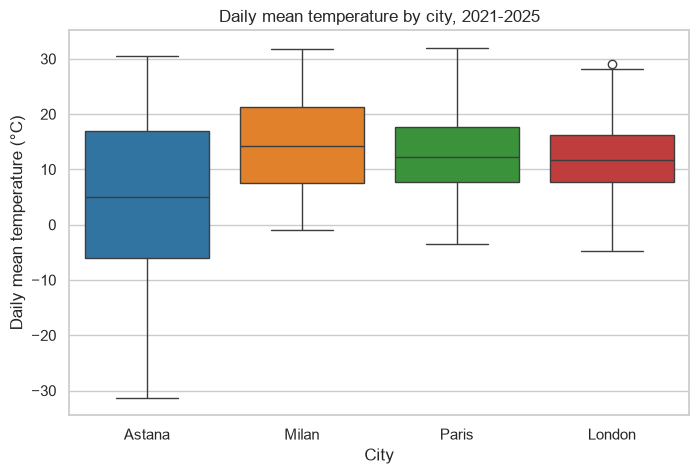

In [8]:
display(an.temperature_variation(weather).round(2))
viz.plot_temperature_boxplot(weather)

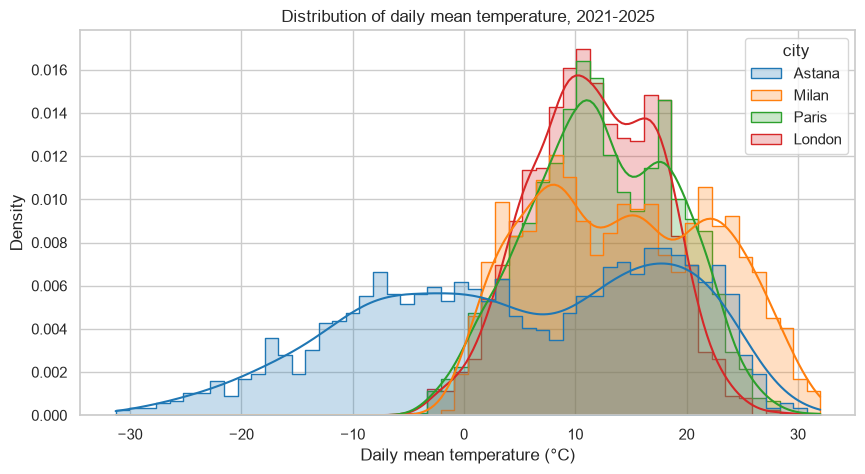

In [9]:
viz.plot_temperature_distribution(weather)

Astana varies most by all three measures. Among the European cities the order depends on the measure: standard deviation and annual amplitude rank Milan > Paris > London, while the range puts Milan last (the range depends on only two days). The temperature distribution and boxplot mix seasonal and day-to-day variation, so Astana's large spread mainly reflects its seasonal cycle.

### Q3 - Precipitation

city,Astana,Milan,Paris,London
year,,,,
2021,346.0,1022.0,754.0,783.0
2022,352.0,800.0,713.0,663.0
2023,410.0,1309.0,949.0,781.0
2024,607.0,1780.0,1152.0,894.0
2025,456.0,1566.0,741.0,613.0


city
Milan     1296.0
Paris      862.0
London     747.0
Astana     434.0
dtype: float64

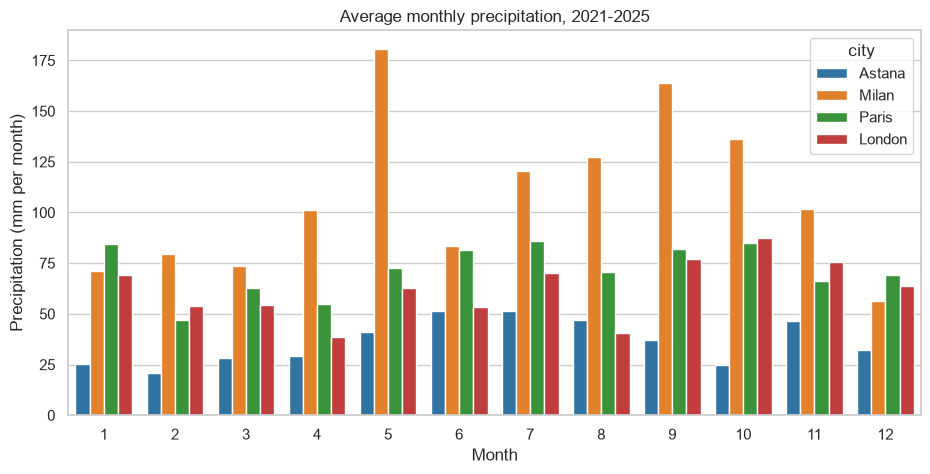

In [10]:
display(an.annual_total(weather, "precipitation_sum").round(0))
display(an.annual_total(weather, "precipitation_sum").mean().round(0).sort_values(ascending=False))
viz.plot_monthly_precipitation(weather)

Mean annual precipitation: Milan (about 1295 mm), Paris (about 862 mm), London (about 747 mm), Astana (about 434 mm). Milan is first and Astana last in every year; Paris and London swap places (London is higher than Paris in 2021, Paris higher in the other four years). With only five years, one unusual year can dominate a monthly average (for example May 2024 in Milan, 372 mm).

### Q4 - Seasonal patterns

season,Winter,Spring,Summer,Autumn
city,,,,
Astana,-11.64,5.70,20.12,4.57
Milan,4.85,13.46,24.60,14.39
Paris,5.67,11.24,19.93,12.92
London,5.92,10.22,18.11,12.43


season,Winter,Spring,Summer,Autumn
city,,,,
Astana,78.0,98.0,149.0,108.0
Milan,207.0,356.0,331.0,402.0
Paris,200.0,190.0,238.0,233.0
London,186.0,156.0,164.0,241.0


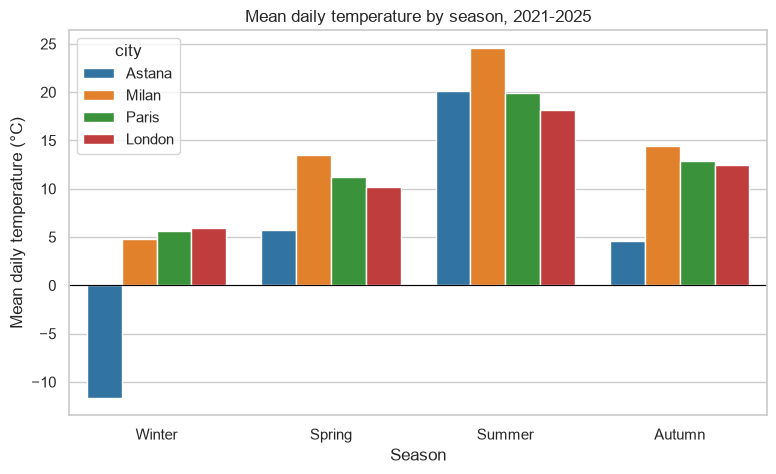

In [11]:
display(an.seasonal_mean(weather, "temperature_2m_mean").round(2))
display(an.seasonal_precipitation(weather).round(0))
viz.plot_seasonal_temperature(weather)

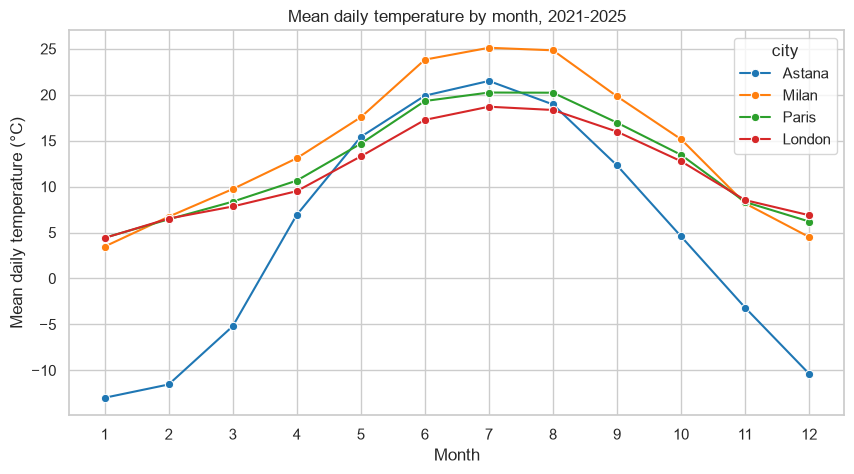

In [12]:
viz.plot_monthly_temperature(weather)

Winter is where Astana differs most (about -11.6 °C against +4.9 to +5.9 °C in the European cities); summer in Astana (20.1 °C) is similar to Paris (19.9 °C), warmer than London (18.1 °C) and cooler than Milan (24.6 °C). In the European cities autumn is warmer than spring; in Astana spring is slightly warmer than autumn. Milan receives the most precipitation in every season, Astana the least, with Astana's maximum in summer.

### Q5 - Rainy days

In [13]:
display(an.rainy_days_per_year(weather).round(1))
an.rainy_days_by_year(weather, 1.0)

,rain_sum >= 0.1 mm,rain_sum >= 1.0 mm,rain_sum >= 5.0 mm
city,,,
Astana,121.2,59.6,18.8
Milan,179.0,119.0,69.6
Paris,214.8,138.8,58.4
London,221.4,130.6,47.8


city,Astana,Milan,Paris,London
year,,,,
2021,39,105,137,136
2022,50,91,116,122
2023,64,116,145,142
2024,85,142,176,147
2025,60,141,120,106


Astana has the fewest rainy days at every threshold (and in every single year at the 1 mm threshold). The city with the most rainy days depends on the threshold: London for >= 0.1 mm, Paris for >= 1 mm and Milan for >= 5 mm. Paris and London are close at 1 mm (Paris leads in three of the five years, and the gap is mostly due to 2024 and 2025), so no single winner is claimed at that threshold.

### Q6 - Temperature and precipitation

,pearson,spearman
Astana,0.090,0.080
Milan,0.040,0.081
Paris,0.069,0.038
London,0.023,0.021


,Winter,Spring,Summer,Autumn
Astana,0.459,-0.010,-0.245,-0.013
Milan,0.143,0.026,-0.353,0.092
Paris,0.260,0.070,-0.164,0.095
London,0.250,0.019,-0.183,0.069


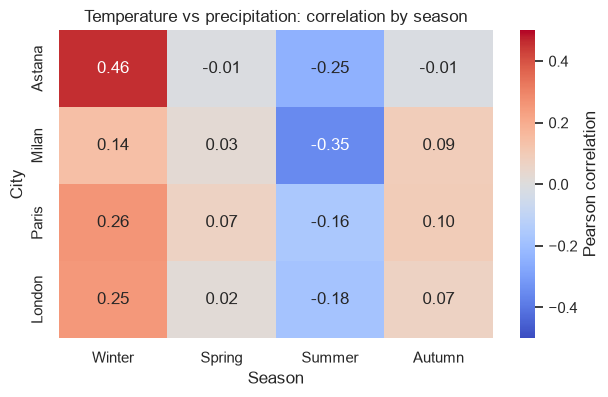

In [14]:
display(an.overall_correlation(weather).round(3))
display(an.seasonal_correlation(weather).round(3))
viz.plot_seasonal_correlation_heatmap(weather)

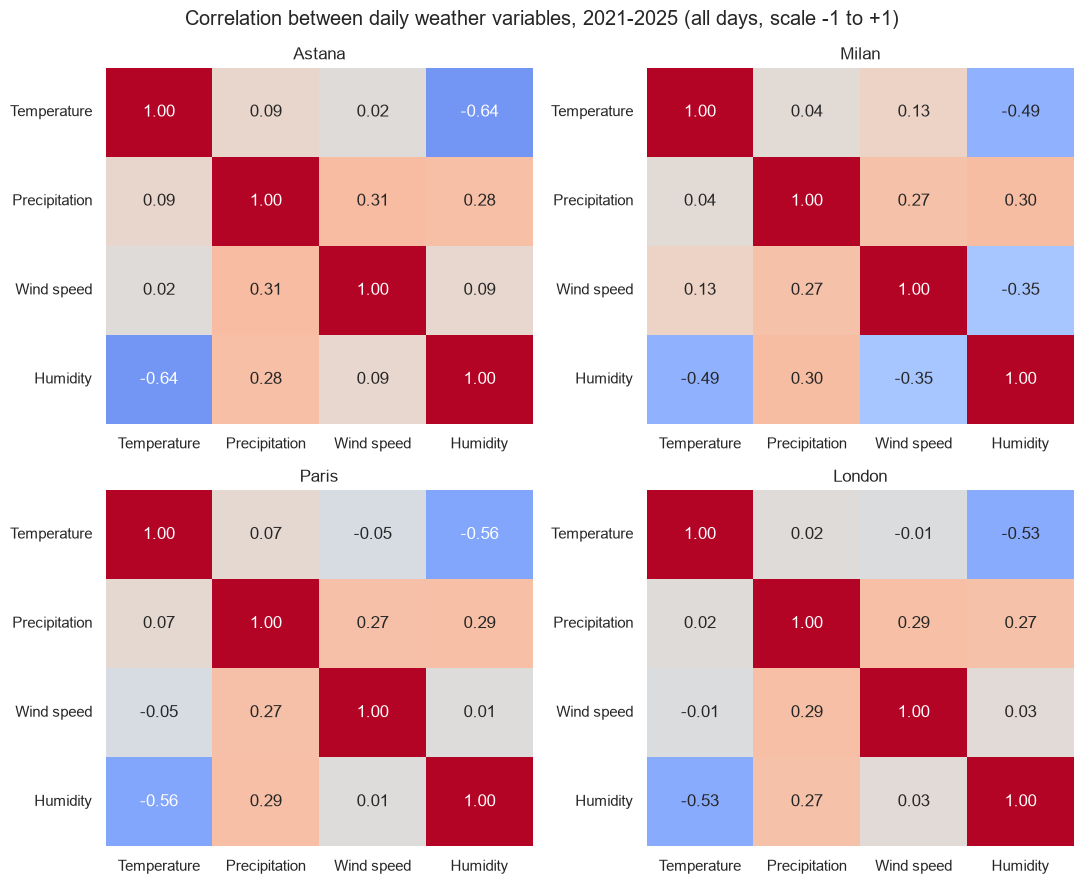

In [15]:
viz.plot_variable_correlation_heatmaps(weather)

Over all days, the correlation between temperature and precipitation is close to zero in every city (|r| < 0.1). Within seasons the picture changes: it is positive in winter (up to 0.46 in Astana) and negative in summer (down to -0.35 in Milan), so the overall value hides opposite seasonal relationships. Correlation does not imply causation, and neighbouring days are not independent.

Among the four variables, the strongest relationship is the negative one between temperature and relative humidity in every city (-0.49 to -0.64). Precipitation correlates positively with wind speed and humidity (about 0.27-0.31). Milan is the only city where wind speed and humidity are clearly negatively correlated (-0.35).

### Q7 - Wind

,mean,median,p95,max,days_ge_40_kmh_per_year
city,,,,,
Astana,20.0,19.2,33.3,52.9,3.6
Milan,13.0,11.8,23.7,54.5,0.8
Paris,18.2,17.1,31.1,52.4,2.4
London,20.5,19.3,35.4,68.0,7.0


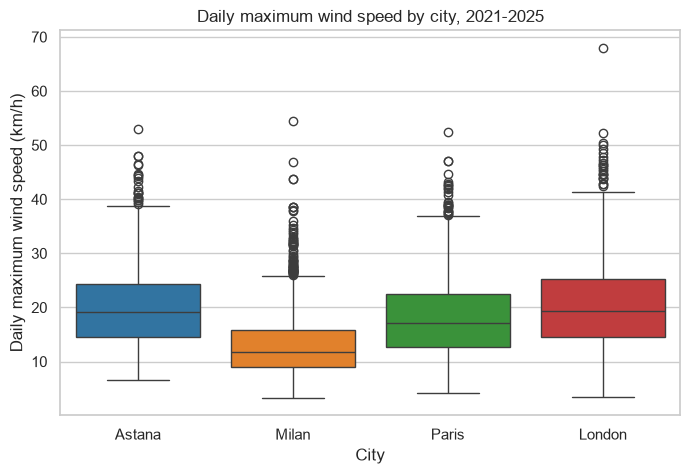

In [16]:
display(an.wind_statistics(weather).round(1))
viz.plot_wind_boxplot(weather)

London is highest on every measure (mean 20.5 km/h, 95th percentile 35.4 km/h, maximum 68.0 km/h, about 7 days per year at or above 40 km/h), followed by Astana, Paris and Milan. London and Astana are almost equal on typical days; the difference is in strong-wind days. The single-day maximum is the least reliable measure, because it depends on one day: Milan, the calmest city, has a higher maximum (54.5 km/h) than Astana (52.9) and Paris (52.4). The variable is the daily maximum of the regular 10 m wind speed, not gusts.

### Q8 - Astana compared with the European cities

In [17]:
an.astana_vs_europe(weather).round(2)

,Astana,European mean,Astana minus Europe
mean_temp_c,4.77,12.85,-8.08
temp_std_c,13.55,6.74,6.81
winter_temp_c,-11.64,5.48,-17.11
summer_temp_c,20.12,20.88,-0.76
annual_precip_mm,434.10,968.05,-533.95
rainy_days_ge_1mm,59.60,129.47,-69.87
mean_humidity_pct,68.63,76.21,-7.58
mean_wind_kmh,19.98,17.26,2.72


Astana is about 8 °C colder than the European mean, almost entirely because of winter (about 17 °C colder); its summer mean is only about 0.8 °C below the European mean (but 4.5 °C below Milan and 2.0 °C above London). Its temperature standard deviation is about twice as large. Annual precipitation (434 mm against 968 mm) and the number of rainy days (59.6 against 129.5 per year) are less than half of the European values, and mean relative humidity is about 7.6 percentage points lower. The mean daily maximum wind speed is 2.7 km/h higher, but this is driven by calm Milan: Astana is slightly below London and above Paris. "Europe" here means only Milan, Paris and London.

## 5. Limitations

- **Short period.** Five years describe 2021-2025, not the long-term climate; single years or events can dominate monthly and seasonal averages (for example May 2024 in Milan).
- **Reanalysis data.** Values are model-based grid-cell estimates, not station measurements, and may shift the timing or smooth the peaks of local events. Absolute totals (especially precipitation) should not be treated as station records.
- **Day boundaries.** The UTC offset is fixed per request, so summer days in the European cities are shifted by about one hour.
- **Wind.** Only the daily maximum of the regular 10 m wind speed was collected, not gusts.
- **Definitions.** Results for "rainy days" and "variation" depend on the chosen threshold and measure; the alternatives are shown above.
- **Correlation.** Correlations are descriptive and do not show causes.

## 6. Conclusions: answers to the research questions (2021-2025)

**1. Highest average annual temperature: Milan.** Mean temperatures are Milan 14.4 °C, Paris 12.5 °C, London 11.7 °C and Astana 4.8 °C. The order is the same in each of the five years, and Milan is 1.7-2.1 °C warmer than Paris every year.

**2. Greatest temperature variation: Astana.** Astana is first by all three measures (standard deviation 13.6 °C, range 61.8 °C, annual amplitude 34.5 °C); its standard deviation is about twice that of the European cities (5.7-8.1 °C). Among Milan, Paris and London the order depends on the measure. The spread mainly reflects the seasonal cycle.

**3. Highest precipitation: Milan.** Mean annual totals are about 1295 mm (Milan), 862 mm (Paris), 747 mm (London) and 434 mm (Astana). Milan is first and Astana last in every year; Paris and London swap places (London is higher in 2021 only). These are reanalysis estimates, so the absolute values should not be read as station records.

**4. Seasonal temperature patterns.** Astana has by far the largest seasonal contrast: its summer mean minus its winter mean is about 31.8 °C, against 19.8 °C in Milan, 14.3 °C in Paris and 12.2 °C in London. Winter: Astana -11.6 °C versus +4.9 to +5.9 °C in the European cities. Spring: 5.7 °C versus 10.2-13.5 °C. Summer: Astana (20.1 °C) is similar to Paris (19.9 °C), warmer than London (18.1 °C) and cooler than Milan (24.6 °C). Autumn: 4.6 °C versus 12.4-14.4 °C. In the European cities autumn is warmer than spring; in Astana spring is slightly warmer than autumn.

**5. Most rainy days: it depends on the definition.** With rain_sum >= 0.1 mm London has the most (221 days per year), with >= 1 mm Paris (139, London 131) and with >= 5 mm Milan (70). Astana has the fewest at every threshold. Milan has fewer light-rain days but more heavy-rain days, which is consistent with its highest precipitation totals. At the 1 mm threshold Paris and London are close and no single winner is claimed.

**6. Temperature and precipitation: no meaningful overall relationship, but a seasonal one.** Over all days the correlation is close to zero in every city (Pearson 0.02-0.09, Spearman 0.02-0.08). Within seasons it is positive in winter (0.14-0.46, strongest in Astana), negative in summer (-0.16 to -0.35, strongest in Milan) and below 0.1 in absolute value in spring and autumn. Opposite seasonal relationships cancel out in the overall value. Even the strongest case (Astana, winter, r = 0.46) explains only about 21% of the variation, and correlation does not show causes.

**7. Strongest winds: London.** London is highest on every measure of the daily maximum 10 m wind speed (mean 20.5 km/h, 95th percentile 35.4 km/h, maximum 68.0 km/h, about 7 days per year at or above 40 km/h), followed by Astana (20.0; 33.3; 3.6 days), Paris (18.2; 31.1; 2.4 days) and Milan (13.0; 23.7; 0.8 days). London and Astana are almost equal on typical days; the difference is in strong-wind days. Wind gusts were not collected.

**8. Astana compared with the European cities.** Astana is about 8.1 °C colder on average (4.8 °C versus 12.9 °C), almost entirely because of winter (about 17 °C colder), while its summer mean is only 0.8 °C below the European mean. Its temperature standard deviation is about twice as large. It receives less than half of the precipitation (434 mm versus 968 mm per year), has less than half the rainy days (59.6 versus 129.5 days with at least 1 mm), and mean relative humidity is about 7.6 percentage points lower. Wind speed does not separate Astana clearly from the European cities (Astana is slightly below London and above Paris). "European" here means only Milan, Paris and London.

**Overall.** In 2021-2025 the four locations form a gradient from Milan (warmest and wettest) through Paris and London (milder, similar to each other, windiest in London) to Astana, which is much colder in winter, far drier and has a much larger seasonal range, but summers comparable to the European cities. These conclusions describe reanalysis data for five years and four locations (see the limitations above), not the long-term climate of the cities.